# Communicate with a vLLM-served Qwen2.5-VL model for V-STaR

Sanity-check script: pick a V-STaR sample, overlay bbox/mask annotations on the video, save it to disk, then send it to the local vLLM server and print the model's answer.

## 1. Load the V-STaR test set

In [1]:
import json
import datasets

dataset = datasets.load_dataset("json", data_files="/projects/torresani-lab/ajay/datasets/V-STaR/V_STaR_test_with_qid.json", split="train")
print(len(dataset))

zeroshot_results = json.load(open("/scratch/rajendrakumar.a/visual-grounded-vlm/results/qwen25vl7bi_vstar_zeroshot/2026-05-18_18-35-15/results.json"))
print(len(zeroshot_results))

2094
2094


## 2. Pick a sample and decode its video

Loads imports, selects `dataset[idx]`, and decodes the video frames at the same `min_pixels`/`max_pixels` budget used during training.

In [18]:
import os
import sys
import importlib

import numpy as np
import torch
from qwen_vl_utils import fetch_video

sys.path.append("/projects/torresani-lab/ajay/visual-grounded-vlm/")
import src.utils.annotation_utils
importlib.reload(src.utils.annotation_utils)
from src.utils.annotation_utils import load_mask_annotations, annotate_frames

# Pick a sample and decode its video at fixed token budget.
idx = 90
sample = dataset[idx]
zeroshot_answer = zeroshot_results[idx]['generated_answer']
print(sample['vid'], sample['qid'])

video_path = os.path.join("/projects/torresani-lab/ajay/datasets/V-STaR/videos", sample['vid'] + ".mp4")
video_input = fetch_video({
    "video": video_path,
    "min_pixels": 128 * 28 * 28,
    "max_pixels": 128 * 28 * 28,
    "fps": 1,
})
print("video_input:", video_input.shape)

5421648216 5421648216_0
video_input: torch.Size([44, 3, 224, 420])


## 3. Overlay annotations on the decoded frames

Loads the saved per-frame mask JSON for this `qid` and draws the chosen annotation type (`bbox` here) on top of the decoded frames.

In [19]:
annotation_root = "/scratch/rajendrakumar.a/visual-grounded-vlm/annotations/vstar/uniform_sample_cap_768/2026-05-19_19-14-38"
annotation_type = "bbox" # "bbox" | "mask" | "outline"

annotation_path = os.path.join(annotation_root, "masks", f"{sample['qid']}.json")
record = load_mask_annotations(annotation_path)

annotated_input = annotate_frames(video_input, record["masks_np"], annotation_type=annotation_type)
annotated_input = torch.tensor(np.array(annotated_input)).permute(0, 3, 1, 2).to(torch.float32)
print("annotated_input:", annotated_input.shape)

annotated_input: torch.Size([44, 3, 224, 420])


## 4. Write the annotated video to disk

vLLM's chat endpoint reads videos by `file://` URL, so we materialize the annotated frames as an mp4 in `dump/`.

In [20]:
from torchcodec.encoders import VideoEncoder

output_video_path = f"/projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serve/dump/ann_{sample['qid']}.mp4"
VideoEncoder(annotated_input.to(torch.uint8), frame_rate=4).to_file(output_video_path)
print("wrote:", output_video_path)

wrote: /projects/torresani-lab/ajay/visual-grounded-vlm/scripts/vllm_serve/dump/ann_5421648216_0.mp4


## 5. Preview the first annotated frame

Quick visual check that the annotation overlay landed correctly before sending the video to the model.

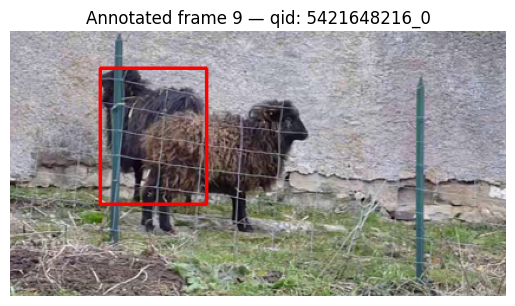

In [21]:
import matplotlib.pyplot as plt

random_idx = np.random.randint(0, annotated_input.shape[0])
any_frame = annotated_input[random_idx].permute(1, 2, 0).numpy().astype(np.uint8)
plt.imshow(any_frame)
plt.title(f"Annotated frame {random_idx} — qid: {sample['qid']}")
plt.axis('off')
plt.show()

## 6. Build the chat request

Reads the system prompt, points the OpenAI client at the local vLLM server, and assembles the `(system, user-question + video)` message. Switch `model` between `"sft"` (LoRA adapter) and the base model id depending on how vLLM was launched.

In [22]:
from openai import OpenAI

openai_api_key = "EMPTY"
openai_api_base = "http://localhost:8000/v1"

# Use "sft" when serving with LoRA (matches LORA_NAME in vllm_serve.sh).
# Use the base model name ("Qwen/Qwen2.5-VL-7B-Instruct") when serving without LoRA.
model = "sft"

with open("/projects/torresani-lab/ajay/visual-grounded-vlm/prompts/train/openo3_red_bbox_stqa.md", "r") as f:
    SYSTEM_PROMPT = f.read()

message = [
    {
        "role": "system",
        "content": [{"type": "text", "text": SYSTEM_PROMPT}],
    },
    {
        "role": "user",
        "content": [
            {
                "type": "text", 
                "text": sample['question']
                # "text": "what does the red bounding box represent in the video?"
            },
            {
                "type": "video_url",
                "video_url": {"url": "file://" + output_video_path},
                "VIDEO_MIN_PIXELS": 128 * 28 * 28,
                "VIDEO_MAX_PIXELS": 128 * 28 * 28,
                "fps": 1,
            },
        ],
    },
]

client = OpenAI(api_key=openai_api_key, base_url=openai_api_base)

## 7. Send the request and print the response

In [25]:
chat_response = client.chat.completions.create(
    model=model,
    messages=message,
    max_tokens=768,
    seed=42,
    temperature=0.5,
    top_p=0.95,
    extra_body={
        "top_k": 20,
    },
)
response_text = chat_response.choices[0].message.content
print(response_text)

<think>
At <t>5</t>s, I see two sheep behind a fence. One has black and white fur, while the other is entirely white. The black and white sheep is facing towards the right side of the frame, indicating it's watching something in that direction. There's no visible interaction with the white sheep, so it seems the black and white sheep is observing its surroundings.
</think>
<answer>
The black and white sheep is watching the white sheep.</answer>


In [24]:
print(f"Question: {sample['question']}")
print("Ground truth answer:", sample['answer'])
print("Zeroshot answer:", zeroshot_answer)

Question: what watches the other white goat?
Ground truth answer: there is a black goat watching another white goat.
Zeroshot answer: The other white goat is watched by the black goat.
